# Chapter 14 — Example 14.3
## Complete Pipeline: Surrogate + NSGA-II + Exact Assessment
Book: *Four-Bar Mechanisms: Design with GA and Neural Networks*

In [ ]:
from numpy import *
random.seed(7)


## 1. Basis functions (kinematics, Hausdorff, μ deficit)

In [12]:
from numpy import *

def fourbar_positions(a, b, c, d=100.0, n=36):
    theta2 = linspace(0, 2*pi, n, endpoint=False)
    pts = []
    for t2 in theta2:
        K1=d/a; K2=d/c; K3=(a**2-b**2+c**2+d**2)/(2*a*c)
        A=cos(t2)-K1-K2*cos(t2)+K3; B=-2*sin(t2)
        C=K1-(K2+1)*cos(t2)+K3; disc=B**2-4*A*C
        if disc<0 or abs(A)<1e-10: pts.append((nan,nan)); continue
        t4=2*arctan2(-B-sqrt(disc),2*A)
        pts.append((c*cos(t4)+d, c*sin(t4)))
    pts=array(pts); mask=~isnan(pts[:,0])
    return pts[mask] if mask.sum()>3 else None

def hausdorff(X, Y):
    if X is None or Y is None: return 1e6
    # Use list comprehensions explicitly instead of generator expressions
    # to ensure compatibility with overridden numpy.min / numpy.max
    d1 = [min([sqrt(sum((x-y)**2)) for y in Y]) for x in X]
    d2 = [min([sqrt(sum((x-y)**2)) for x in X]) for y in Y]
    return max([max(d1), max(d2)])

def mu_deficit(a,b,c,d=100.0,mu_min=40.0,n=36):
    deficit=0.0
    for t2 in linspace(0,2*pi,n,endpoint=False):
        num=b**2+c**2-(d-a*cos(t2))**2-(a*sin(t2))**2
        den=2*b*c
        if abs(den)<1e-10: continue
        mu=degrees(arccos(clip(num/den,-1,1)))
        mu=mu if mu<=90 else 180-mu
        deficit=maximum(deficit,maximum(0,mu_min-mu))
    return deficit

def grashof_ok(a,b,c,d=100.0):
    L=sorted([a,b,c,d]); return L[0]+L[3]<=L[1]+L[2]

theta_ref=linspace(0,2*pi,36,endpoint=False)
TRAJ_REF=column_stack([130+30*cos(theta_ref),30*sin(theta_ref)])

## 2. Phase 1 — Surrogate Training

In [21]:
from numpy import *
import numpy.random as random

def relu(x): return maximum(0,x)
def relu_d(x): return where(x>0,1.0,0.0)

class MLP:
    def __init__(self,layers,lr=5e-4):
        self.lr=lr; self.W,self.b=[],[]
        for i in range(len(layers)-1):
            self.W.append(random.randn(layers[i],layers[i+1])*sqrt(2/layers[i]))
            self.b.append(zeros(layers[i+1]))
    def forward(self,X):
        self.zs,self.as_=[],[X]; a=X
        for k,(W,b) in enumerate(zip(self.W,self.b)):
            z=a@W+b; self.zs.append(z)
            a=relu(z) if k<len(self.W)-1 else z; self.as_.append(a)
        return a
    def backward(self,X,y):
        m=len(X); delta=(self.as_[-1]-y.reshape(-1,1))/m
        for k in range(len(self.W)-1,-1,-1):
            dW=self.as_[k].T@delta; db=delta.sum(axis=0)
            if k>0: delta=(delta@self.W[k].T)*relu_d(self.zs[k-1])
            self.W[k]-=self.lr*dW; self.b[k]-=self.lr*db
    def fit(self,X,y,epochs=400,batch=64):
        n=len(X)
        for ep in range(1,epochs+1):
            idx=random.permutation(n)
            for i in range(0,n,batch):
                xb=X[idx[i:i+batch]]; yb=y[idx[i:i+batch]]
                self.forward(xb); self.backward(xb,yb)
    def predict(self,X): return self.forward(X).ravel()

# Reset and generate dataset cleanly
X_data,y1_data,y2_data=[],[],[]
while len(X_data)<1200:
    abc=random.uniform(20,90,3)
    a,b,c=abc
    if grashof_ok(a,b,c):
        pts=fourbar_positions(a,b,c)
        if pts is not None:
            X_data.append(abc)
            y1_data.append(hausdorff(pts,TRAJ_REF))
            y2_data.append(mu_deficit(a,b,c))
X_data=array(X_data); y1_data=array(y1_data); y2_data=array(y2_data)
Xm,Xs=X_data.mean(0),X_data.std(0)+1e-8
Xn=(X_data-Xm)/Xs
mlp1=MLP([3,64,64,1]); mlp2=MLP([3,64,64,1])
mlp1.fit(Xn,y1_data); mlp2.fit(Xn,y2_data)
print('Phase 1: Surrogates trained.')

Phase 1: Surrogates trained.


## 3. Phase 2 — NSGA-II with surrogate (200 generations)

In [22]:
from numpy import *
import numpy.random as random

def dominates(u,v): return all(u<=v) and any(u<v)

def pareto_front(pop,pop_f):
    N=len(pop); dom=[]
    for i in range(N):
        dominated=False
        for j in range(N):
            if i!=j and dominates(pop_f[j],pop_f[i]): dominated=True; break
        if not dominated: dom.append(i)
    return dom

POP=80; NGEN=200; PM=0.15
pop=[]
while len(pop)<POP:
    abc=random.uniform(20,90,3)
    if grashof_ok(*abc): pop.append(abc)
pop=array(pop)

def eval_surrogate(ind):
    xn=(ind-Xm)/Xs
    val1 = mlp1.predict(xn.reshape(1,-1))[0]
    val2 = mlp2.predict(xn.reshape(1,-1))[0]
    f1 = val1 if val1 > 0 else 0.0
    f2 = val2 if val2 > 0 else 0.0
    return array([f1,f2])

pop_f=array([eval_surrogate(ind) for ind in pop])
print('Phase 2: NSGA-II with surrogate (200 generations) ...')
for gen in range(NGEN):
    offspring=[]
    while len(offspring)<POP:
        i1,i2=random.choice(len(pop),2,replace=False)
        p1=pop[i1] if pop_f[i1,0]<pop_f[i2,0] else pop[i2]
        i3,i4=random.choice(len(pop),2,replace=False)
        p2=pop[i3] if pop_f[i3,0]<pop_f[i4,0] else pop[i4]
        eta=15; u=random.rand(3)
        beta=where(u<=0.5,(2*u)**(1/(eta+1)),(1/(2*(1-u)))**(1/(eta+1)))
        child=clip(0.5*((1+beta)*p1+(1-beta)*p2),20,90)
        if random.rand()<PM:
            u2=random.rand(3); eta2=20
            delta=where(u2<0.5,(2*u2)**(1/(eta2+1))-1,1-(2*(1-u2))**(1/(eta2+1)))
            child=clip(child+delta*70,20,90)
        if grashof_ok(*child):
            offspring.append(child)
    offspring=array(offspring)
    off_f=array([eval_surrogate(ind) for ind in offspring])
    combined=vstack([pop,offspring]); combined_f=vstack([pop_f,off_f])
    fi=pareto_front(combined,combined_f)
    if len(fi)>=POP:
        fi=fi[:POP]
    else:
        rest=[i for i in range(len(combined)) if i not in fi]
        fi=fi+rest[:POP-len(fi)]
    pop=combined[fi]; pop_f=combined_f[fi]
print(f'  {len(pareto_front(pop,pop_f))} candidates in Pareto front (surrogate)')

Phase 2: NSGA-II with surrogate (200 generations) ...
  80 candidates in Pareto front (surrogate)


## 4. Phase 3 — Exact evaluation and selection by ideal point

In [23]:
from numpy import *

cands=pareto_front(pop,pop_f)
print(f'Phase 3: Exact evaluation of the Pareto front ...')
print(f'  {len(cands)} candidates evaluated exactly')

exact_x, exact_f = [], []
for i in cands:
    a,b,c=pop[i]
    pts=fourbar_positions(a,b,c)
    if pts is not None:
        f1=hausdorff(pts,TRAJ_REF)
        f2=mu_deficit(a,b,c)
        exact_x.append(pop[i])
        exact_f.append([f1,f2])
exact_x=array(exact_x); exact_f=array(exact_f)

# Exact Pareto front
final_cands=pareto_front(exact_x,exact_f)
print(f'  Exact Pareto front: {len(final_cands)} solutions')

# Selection by weighted ideal point
w1,w2=0.6,0.4
fmin=exact_f[final_cands].min(0)
fmax=exact_f[final_cands].max(0)+1e-10
fn=(exact_f[final_cands]-fmin)/(fmax-fmin)
scores=w1*fn[:,0]+w2*fn[:,1]
best=final_cands[argmin(scores)]
a,b,c=exact_x[best]
f1,f2=exact_f[best]
print('=======================================================')
print(f'  Compromise Solution (w1={w1}, w2={w2}):')
print(f'  Parameters  : a={a:.1f} mm  b={b:.1f} mm  c={c:.1f} mm')
print(f'  f1 Hausdorff: {f1:.2f} mm')
print(f'  f2 Deficit u: {f2:.2f} degrees')
print(f'  Pareto Front: {len(final_cands)} non-dominated solutions')
print('=======================================================')

Phase 3: Exact evaluation of the Pareto front ...
  80 candidates evaluated exactly
  Exact Pareto front: 3 solutions
  Compromise Solution (w1=0.6, w2=0.4):
  Parameters  : a=90.0 mm  b=55.9 mm  c=31.0 mm
  f1 Hausdorff: 31.02 mm
  f2 Deficit u: 40.00 degrees
  Pareto Front: 3 non-dominated solutions


## 5. Final display

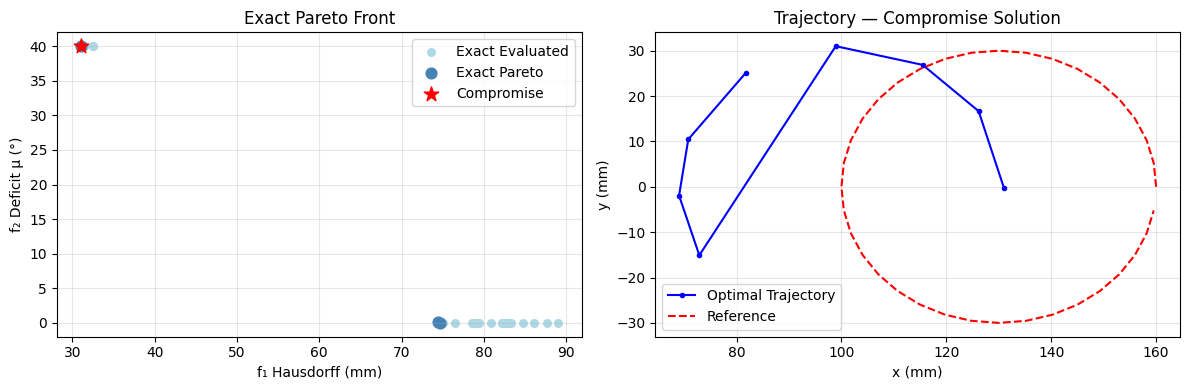

In [24]:
from numpy import *
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1,2, figsize=(12,4))
ax=axes[0]
ax.scatter(exact_f[:,0],exact_f[:,1],c='lightblue',s=30,label='Exact Evaluated')
ax.scatter(exact_f[final_cands,0],exact_f[final_cands,1],c='steelblue',s=60,label='Exact Pareto')
ax.scatter(f1,f2,c='red',s=120,zorder=5,marker='*',label='Compromise')
ax.set_xlabel('f₁ Hausdorff (mm)'); ax.set_ylabel('f₂ Deficit μ (°)')
ax.set_title('Exact Pareto Front'); ax.legend(); ax.grid(alpha=0.3)

ax=axes[1]
pts_best=fourbar_positions(a,b,c)
if pts_best is not None:
    ax.plot(pts_best[:,0],pts_best[:,1],'b-o',ms=3,label='Optimal Trajectory')
ax.plot(TRAJ_REF[:,0],TRAJ_REF[:,1],'r--',label='Reference')
ax.set_xlabel('x (mm)'); ax.set_ylabel('y (mm)')
ax.set_title('Trajectory — Compromise Solution'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [25]:
# Simple test case to verify correct function behavior
a_test, b_test, c_test = 40.0, 80.0, 70.0

print("1. Verifying grashof_ok:")
ok_grashof = grashof_ok(a_test, b_test, c_test)
print(f"   Grashof OK: {ok_grashof}")

print("\n2. Verifying fourbar_positions:")
pts_test = fourbar_positions(a_test, b_test, c_test)
if pts_test is not None:
    print(f"   Successful calculation. Generated {len(pts_test)} valid positions.")
    print(f"   First few positions: \n{pts_test[:3]}")
else:
    print("   Configuration does not produce valid positions.")

print("\n3. Verifying hausdorff:")
if pts_test is not None:
    h_val = hausdorff(pts_test, TRAJ_REF)
    print(f"   Calculated Hausdorff distance: {h_val:.4f} mm")

print("\n4. Verifying mu_deficit:")
def_val = mu_deficit(a_test, b_test, c_test)
print(f"   Transmission angle deficit: {def_val:.4f} degrees")

1. Verifying grashof_ok:
   Grashof OK: True

2. Verifying fourbar_positions:
   Successful calculation. Generated 36 valid positions.
   First few positions: 
[[82.5        67.77720856]
 [89.60620698 69.22404977]
 [94.60977121 69.79215883]]

3. Verifying hausdorff:
   Calculated Hausdorff distance: 107.1341 mm

4. Verifying mu_deficit:
   Transmission angle deficit: 0.0000 degrees
